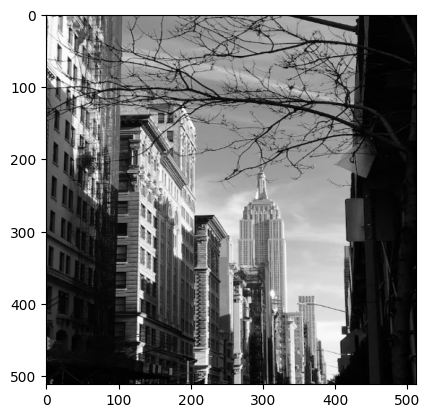

In [15]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap='gray')

In [16]:
image_gray = image_gray.astype(np.float32)
def haar(image):
    h, w = image.shape
    temp = np.zeros((h, w), np.float32)
    res = np.zeros((h, w), np.float32)

    for i in range(h):
        for j in range(w // 2):
            a = image[i, 2 * j]
            b = image[i, 2 * j + 1]
            temp[i, j] = (a + b) / 2
            temp[i, j + w // 2] = (a - b) / 2
    for i in range(h // 2):
        for j in range(w):
            a = temp[2 * i, j]
            b = temp[2 * i + 1, j]
            res[i, j] = (a + b) / 2
            res[i + h // 2, j] = (a - b) / 2

    return res

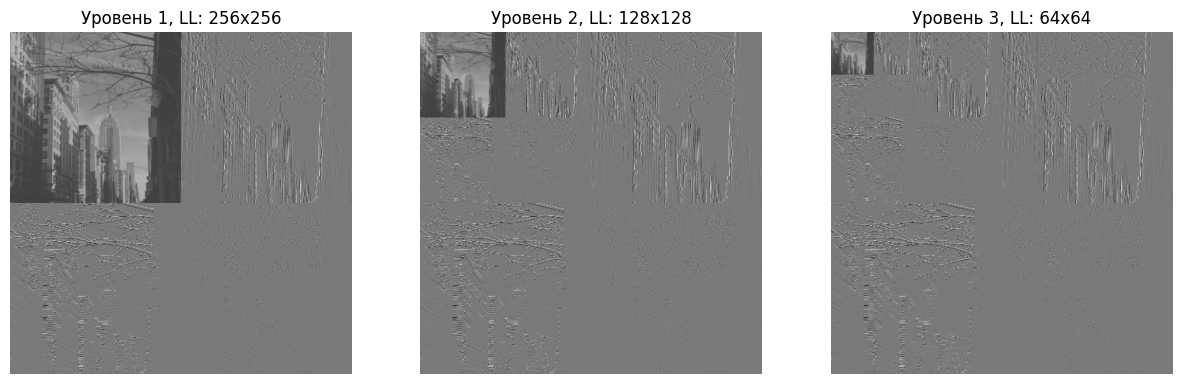

In [17]:
res = image_gray.copy()
n = 512
compressed = []

plt.figure(figsize=(15, 5))
for l in range(1, 4):
    res[:n, :n] = haar(res[:n, :n])
    n //= 2
    compressed.append(res[:n, :n].copy())

    res_show = 128 + 3 * res
    res_show[:n, :n] = res[:n, :n]
    plt.subplot(1, 3, l)
    plt.imshow(res_show, cmap='gray')
    plt.title(f'Уровень {l}, LL: {n}x{n}')
    plt.axis('off')

Ступень 1:  размер (256, 256), меньше в 4 раз(-а)
Ступень 2:  размер (128, 128), меньше в 16 раз(-а)
Ступень 3:  размер (64, 64), меньше в 64 раз(-а)


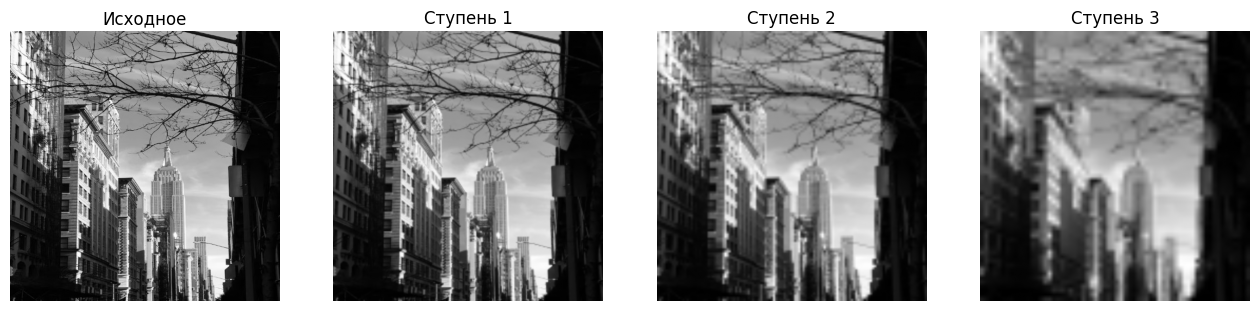

In [18]:
plt.figure(figsize=(16, 5))
plt.subplot(1, 4, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное')
plt.axis('off')


for i in range(3):
    image_decomp = cv2.resize(compressed[i], (512, 512))
    plt.subplot(1, 4, i + 2)
    plt.imshow(image_decomp, cmap='gray')
    plt.title(f'Ступень {i + 1}')
    plt.axis('off')
    print(f'Ступень {i + 1}:  размер {compressed[i].shape}, меньше в {image_gray.size // compressed[i].size} раз(-а)')